# ML-05 — Capstone Modeling Lane

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [ ]:
#login
from google.colab import userdata
from huggingface_hub import login, hf_hub_download
import pandas as pd
import pyarrow.parquet as pq

HF_TOKEN = userdata.get("HF_token")
login(token=HF_TOKEN)


In [ ]:
fact_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    repo_type="dataset",
    filename="fact_content_daily_performance/month=2026-03/data_0.parquet",
    token=HF_TOKEN
)

print("March file downloaded:", fact_path)

# Inspect the file WITHOUT loading the full table into pandas
parquet_file = pq.ParquetFile(fact_path)

print("Rows in file:", parquet_file.metadata.num_rows)
print("Columns:", parquet_file.schema.names)
print("Row groups:", parquet_file.num_row_groups)


fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  124MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

March file downloaded: /root/.cache/huggingface/hub/datasets--FlyRank--internship-warehouse/snapshots/50cbf7c3909d07be4d1b5906b4d09e882e5acbf2/fact_content_daily_performance/month=2026-03/data_0.parquet
Rows in file: 9841378
Columns: ['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events']
Row groups: 85


In [ ]:
from collections import Counter

parquet_file = pq.ParquetFile(fact_path)

flag_counts = {
    col: Counter()
    for col in [
        "client_has_gsc",
        "client_has_ga4",
        "gsc_data_available",
        "ga4_data_available"
    ]
}

missing_counts = Counter()
total_rows = 0

check_cols = [
    "ga4_sessions",
    "ga4_engaged_sessions",
    "sessions_organic",
    "sessions_ai",
    "gsc_impressions",
    "gsc_clicks"
]

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=list(flag_counts.keys()) + check_cols
):
    df_batch = batch.to_pandas()
    total_rows += len(df_batch)

    for col in flag_counts:
        flag_counts[col].update(
            df_batch[col].astype("string").fillna("NULL").tolist()
        )

    for col in check_cols:
        missing_counts[col] += int(df_batch[col].isna().sum())

print("Total rows checked:", total_rows)

print("\nAvailability flag counts:")
for col, counts in flag_counts.items():
    print(f"\n{col}:")
    print(counts)

print("\nMissing-value percentages across the full March file:")
for col in check_cols:
    pct = 100 * missing_counts[col] / total_rows
    print(f"{col}: {pct:.2f}% missing")


Total rows checked: 9841378

Availability flag counts:

client_has_gsc:
Counter({'True': 9841378})

client_has_ga4:
Counter({'True': 6822637, 'False': 3018741})

gsc_data_available:
Counter({'False': 6230317, 'True': 3611061})

ga4_data_available:
Counter({'False': 6408671, 'NULL': 3018741, 'True': 413966})

Missing-value percentages across the full March file:
ga4_sessions: 30.67% missing
ga4_engaged_sessions: 30.67% missing
sessions_organic: 30.67% missing
sessions_ai: 30.67% missing
gsc_impressions: 0.00% missing
gsc_clicks: 0.00% missing


In [ ]:
# Purpose: Check whether the content metadata dataset is still in memory.
# If it is missing, reload only dim_content—not the large performance dataset.

if "dim_content" not in globals():
    from datasets import load_dataset

    dim_content = load_dataset(
        "FlyRank/internship-warehouse",
        "dim_content",
        split="train",
        token=HF_TOKEN
    ).to_pandas()

print("dim_content shape:", dim_content.shape)
print("\nAvailable columns:")
print(dim_content.columns.tolist())


README.md:   0%|          | 0.00/3.04k [00:00<?, ?B/s]

dim_content.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

dim_content.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/519606 [00:00<?, ? examples/s]

dim_content shape: (519606, 26)

Available columns:
['client_hash_id', 'content_hash_id', 'keyword_hash_id', 'url_hash_id', 'keyword_char_count', 'keyword_token_count', 'url_char_count', 'content_created_date', 'content_updated_date', 'content_type', 'search_volume', 'competition', 'competition_level', 'cpc', 'main_intent', 'backlinks', 'category_count', 'keyword_created_date', 'provider_used', 'model_used', 'char_count', 'word_count', 'last_optimized_date', 'optimization_eligible_date', 'is_published', 'is_deleted']


In [ ]:
# Purpose: Measure how many unique content IDs in March performance data
# match the content metadata, without loading the full fact table into memory.

import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(fact_path)

# Collect unique content IDs from the March performance file.
march_content_ids = set()

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["content_hash_id"]
):
    march_content_ids.update(
        batch.column("content_hash_id").to_pylist()
    )

# Collect unique content IDs from the metadata table.
dim_content_ids = set(dim_content["content_hash_id"].dropna().unique())

# Compare the two sets.
matched_ids = march_content_ids & dim_content_ids
unmatched_march_ids = march_content_ids - dim_content_ids
metadata_only_ids = dim_content_ids - march_content_ids

print("Unique content IDs in March performance:", len(march_content_ids))
print("Unique content IDs in dim_content:", len(dim_content_ids))
print("Matched IDs:", len(matched_ids))
print("March IDs missing from metadata:", len(unmatched_march_ids))
print("Metadata IDs not present in March:", len(metadata_only_ids))

if march_content_ids:
    print(
        "March ID match rate:",
        round(100 * len(matched_ids) / len(march_content_ids), 2),
        "%"
    )

Unique content IDs in March performance: 331437
Unique content IDs in dim_content: 519606
Matched IDs: 331437
March IDs missing from metadata: 0
Metadata IDs not present in March: 188169
March ID match rate: 100.0 %


In [ ]:
# Purpose: Audit candidate metadata features for missing values, duplicates,
# and dates later than March 2026 before selecting clustering features.

import pandas as pd

candidate_cols = [
    "content_hash_id",
    "content_type",
    "main_intent",
    "word_count",
    "char_count",
    "search_volume",
    "competition",
    "competition_level",
    "cpc",
    "backlinks",
    "category_count",
    "content_created_date",
    "content_updated_date",
    "last_optimized_date",
    "is_published",
    "is_deleted"
]

print("Missing-value percentage:")
print(
    (dim_content[candidate_cols].isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nDuplicate content_hash_id rows:")
print(dim_content["content_hash_id"].duplicated().sum())

# Convert date columns to datetime for a consistent date audit.
date_cols = [
    "content_created_date",
    "content_updated_date",
    "last_optimized_date"
]

for col in date_cols:
    dates = pd.to_datetime(dim_content[col], errors="coerce")
    print(f"\n{col}:")
    print("Valid dates:", dates.notna().sum())
    print("Latest date:", dates.max())
    print("Dates after 2026-03-31:", (dates > "2026-03-31").sum())


Missing-value percentage:
last_optimized_date     91.26
backlinks               51.48
word_count              34.21
char_count              34.21
main_intent             28.56
competition_level       27.80
search_volume           27.45
competition             27.45
cpc                     27.45
content_hash_id          0.00
content_type             0.00
category_count           0.00
content_created_date     0.00
content_updated_date     0.00
is_published             0.00
is_deleted               0.00
dtype: float64

Duplicate content_hash_id rows:
0

content_created_date:
Valid dates: 519606
Latest date: 2026-07-06 00:00:00
Dates after 2026-03-31: 86172

content_updated_date:
Valid dates: 519606
Latest date: 2026-07-06 00:00:00
Dates after 2026-03-31: 382739

last_optimized_date:
Valid dates: 45396
Latest date: 2026-07-06 00:00:00
Dates after 2026-03-31: 45396


In [ ]:
# Purpose: Inspect category distributions and distinguish missing numeric values
# from genuine zeros before finalizing the clustering feature set.

print("Top content types:")
print(dim_content["content_type"].value_counts(dropna=False).head(15))

print("\nTop main intents:")
print(dim_content["main_intent"].value_counts(dropna=False).head(15))

numeric_cols = [
    "word_count",
    "char_count",
    "search_volume",
    "backlinks",
    "category_count"
]

print("\nNumeric feature summary:")
display(dim_content[numeric_cols].describe().T)

print("\nZero-value percentages:")
for col in numeric_cols:
    zero_pct = (dim_content[col] == 0).mean() * 100
    print(f"{col}: {zero_pct:.2f}% zero")

Top content types:
content_type
keyword article       459174
feedly article         57024
comparison article      3408
Name: count, dtype: int64

Top main intents:
main_intent
informational    260233
None             148398
transactional     55956
commercial        52762
navigational       2257
Name: count, dtype: int64

Numeric feature summary:


,count,mean,std,min,25%,50%,75%,max
word_count,341838.0,2472.052680,1087.753954,0.0,1539.0,2593.0,3038.0,29341.0
char_count,341838.0,16433.770789,7695.482232,0.0,10198.0,16791.0,20110.0,357575.0
search_volume,376984.0,209.574544,3207.498742,0.0,0.0,10.0,20.0,368000.0
backlinks,252132.0,456.128135,24042.051239,0.0,0.0,0.0,0.0,4269360.0
category_count,519606.0,1.048621,2.091212,0.0,0.0,0.0,0.0,18.0



Zero-value percentages:
word_count: 0.00% zero
char_count: 0.00% zero
search_volume: 31.49% zero
backlinks: 37.77% zero
category_count: 75.89% zero


In [ ]:
# Purpose: Aggregate March daily performance into one row per content ID.
# Sum monthly metrics and preserve availability information so missing data
# is not automatically interpreted as zero performance.

import pyarrow.parquet as pq
import pandas as pd

parquet_file = pq.ParquetFile(fact_path)

performance_cols = [
    "content_hash_id",
    "gsc_impressions",
    "gsc_clicks",
    "gsc_sum_position",
    "ga4_sessions",
    "ga4_engaged_sessions",
    "sessions_organic",
    "sessions_ai",
    "client_has_gsc",
    "client_has_ga4",
    "gsc_data_available",
    "ga4_data_available"
]

# Read only relevant columns in batches, then aggregate each batch.
# The intermediate data is much smaller than the full 9.8M-row dataset.
parts = []

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=performance_cols
):
    batch_df = batch.to_pandas()

    grouped = batch_df.groupby("content_hash_id", dropna=False).agg(
        gsc_impressions=("gsc_impressions", "sum"),
        gsc_clicks=("gsc_clicks", "sum"),
        gsc_sum_position=("gsc_sum_position", "sum"),
        ga4_sessions=("ga4_sessions", "sum"),
        ga4_engaged_sessions=("ga4_engaged_sessions", "sum"),
        sessions_organic=("sessions_organic", "sum"),
        sessions_ai=("sessions_ai", "sum"),
        client_has_gsc=("client_has_gsc", "max"),
        client_has_ga4=("client_has_ga4", "max"),
        gsc_available_days=("gsc_data_available", "sum"),
        ga4_available_days=("ga4_data_available", "sum")
    )

    parts.append(grouped)

# Combine batch-level aggregates into a final monthly content-level table.
march_performance = pd.concat(parts).groupby(level=0).sum(min_count=1)

print("Aggregated shape:", march_performance.shape)
print("\nSample rows:")
display(march_performance.head())

print("\nMissing percentages after aggregation:")
display((march_performance.isna().mean() * 100).round(2))

Aggregated shape: (331437, 11)

Sample rows:


,gsc_impressions,gsc_clicks,gsc_sum_position,ga4_sessions,ga4_engaged_sessions,sessions_organic,sessions_ai,client_has_gsc,client_has_ga4,gsc_available_days,ga4_available_days
content_hash_id,,,,,,,,,,,
content_000005d4ced12088,86,0,6199,0.0,0.0,0.0,0.0,28,28,24,0
content_00001e488b74b799,0,0,0,0.0,0.0,0.0,0.0,25,25,0,0
content_00007bd2985b77c3,47,0,249,0.0,0.0,0.0,0.0,30,10,23,0
content_00008950670cb6b5,0,0,0,2.0,1.0,0.0,0.0,28,28,0,2
content_0000a348850eb1fc,0,0,0,1.0,0.0,0.0,0.0,26,21,0,1



Missing percentages after aggregation:


,0
gsc_impressions,0.0
gsc_clicks,0.0
gsc_sum_position,0.0
ga4_sessions,0.0
ga4_engaged_sessions,0.0
sessions_organic,0.0
sessions_ai,0.0
client_has_gsc,0.0
client_has_ga4,0.0
gsc_available_days,0.0


In [ ]:
# Purpose: Join March content-level performance with metadata and derive
# availability-aware indicators. Keep IDs for joining, not as clustering features.

# Select metadata fields relevant for the first clustering experiment.
metadata_cols = [
    "content_hash_id",
    "content_type",
    "main_intent",
    "word_count",
    "char_count",
    "search_volume",
    "competition",
    "backlinks",
    "category_count",
    "content_created_date",
    "is_published",
    "is_deleted"
]

metadata = dim_content[metadata_cols].copy()

# Join each content's metadata to its March performance aggregates.
combined = metadata.merge(
    march_performance.reset_index(),
    on="content_hash_id",
    how="inner",
    validate="one_to_one"
)

# Calculate CTR only where impressions are greater than zero.
combined["gsc_ctr"] = (
    combined["gsc_clicks"] /
    combined["gsc_impressions"].where(combined["gsc_impressions"] > 0)
)

# Calculate engagement rate only where GA4 sessions are greater than zero
# AND at least one GA4 data-available day was recorded.
combined["ga4_engagement_rate"] = (
    combined["ga4_engaged_sessions"] /
    combined["ga4_sessions"].where(
        (combined["ga4_sessions"] > 0) &
        (combined["ga4_available_days"] > 0)
    )
)

# Convert date columns for later time-aware checks.
combined["content_created_date"] = pd.to_datetime(
    combined["content_created_date"], errors="coerce"
)

print("Combined shape:", combined.shape)
print("\nGSC available-day counts:")
print(combined["gsc_available_days"].describe())

print("\nGA4 available-day counts:")
print(combined["ga4_available_days"].describe())

print("\nRows with no GA4 available days:",
      (combined["ga4_available_days"] == 0).sum())

print("\nSample:")
display(combined.head())


Combined shape: (331437, 25)

GSC available-day counts:
count    331437.000000
mean         10.895166
std          13.197774
min           0.000000
25%           0.000000
50%           1.000000
75%          28.000000
max          31.000000
Name: gsc_available_days, dtype: float64

GA4 available-day counts:
count     331437
unique        32
top            0
freq      240948
Name: ga4_available_days, dtype: int64

Rows with no GA4 available days: 240948

Sample:


,content_hash_id,content_type,main_intent,word_count,char_count,search_volume,competition,backlinks,category_count,content_created_date,...,ga4_sessions,ga4_engaged_sessions,sessions_organic,sessions_ai,client_has_gsc,client_has_ga4,gsc_available_days,ga4_available_days,gsc_ctr,ga4_engagement_rate
0,content_004e9c4c32e88631,keyword article,informational,3935.0,24997.0,10.0,0.50,0.0,6,2025-10-07,...,0.0,0.0,0.0,0.0,29,0,0,0,NaN,NaN
1,content_0236ef736698e17c,keyword article,transactional,4335.0,27584.0,20.0,0.00,0.0,2,2025-10-07,...,0.0,0.0,0.0,0.0,29,0,0,0,NaN,NaN
2,content_025f6cfd3c298870,keyword article,commercial,3719.0,22998.0,10.0,0.00,0.0,6,2025-10-07,...,0.0,0.0,0.0,0.0,29,0,0,0,NaN,NaN
3,content_0263d5f9b7a2ecd4,keyword article,informational,3246.0,19942.0,0.0,0.00,0.0,0,2025-10-07,...,0.0,0.0,0.0,0.0,29,0,1,0,0.0,NaN
4,content_02752c6c1c60161f,keyword article,commercial,3641.0,22584.0,20.0,0.01,3.0,4,2025-10-07,...,0.0,0.0,0.0,0.0,29,0,0,0,NaN,NaN


In [ ]:
# Purpose: Classify content by actual monthly GSC/GA4 data availability
# and inspect whether recorded metrics are zero or positive within each group.

combined["gsc_status"] = "no_available_days"
combined.loc[combined["gsc_available_days"] > 0, "gsc_status"] = "available"

combined["ga4_status"] = "no_available_days"
combined.loc[combined["ga4_available_days"] > 0, "ga4_status"] = "available"

print("GSC availability groups:")
print(combined["gsc_status"].value_counts(dropna=False))

print("\nGA4 availability groups:")
print(combined["ga4_status"].value_counts(dropna=False))

print("\nGA4 sessions by availability:")
display(
    combined.groupby("ga4_status")["ga4_sessions"]
    .agg(["count", "min", "median", "max"])
)

print("\nGSC impressions by availability:")
display(
    combined.groupby("gsc_status")["gsc_impressions"]
    .agg(["count", "min", "median", "max"])
)


GSC availability groups:
gsc_status
available            176738
no_available_days    154699
Name: count, dtype: int64

GA4 availability groups:
ga4_status
no_available_days    240948
available             90489
Name: count, dtype: int64

GA4 sessions by availability:


,count,min,median,max
ga4_status,,,,
available,90489,0.0,2.0,2730.0
no_available_days,240948,0.0,0.0,0.0



GSC impressions by availability:


,count,min,median,max
gsc_status,,,,
available,176738,1,173.0,617124
no_available_days,154699,0,0.0,0


In [ ]:
# Purpose: Build the final first-experiment dataset using the approved features.
# Restrict to content with available March GSC data and retain only selected columns.

feature_cols = [
    "gsc_impressions",
    "gsc_clicks",
    "gsc_ctr",
    "gsc_sum_position",
    "search_volume",
    "word_count",
    "category_count",
    "content_type",
    "main_intent"
]

# Keep only content with at least one day of available GSC data.
cluster_data = combined.loc[
    combined["gsc_available_days"] > 0
].copy()

# Derive an impressions-weighted average position from summed position data.
# Use NaN when there are no impressions, rather than inventing a position.
cluster_data["gsc_avg_position"] = (
    cluster_data["gsc_sum_position"] /
    cluster_data["gsc_impressions"].where(
        cluster_data["gsc_impressions"] > 0
    )
)

# Use the intended feature list (average position, not raw summed position).
feature_cols = [
    "gsc_impressions",
    "gsc_clicks",
    "gsc_ctr",
    "gsc_avg_position",
    "search_volume",
    "word_count",
    "category_count",
    "content_type",
    "main_intent"
]

cluster_data = cluster_data[
    ["content_hash_id"] + feature_cols
].copy()

print("Final clustering dataset shape:", cluster_data.shape)
print("\nFeature columns:")
print(feature_cols)
print("\nGSC-available content count:", len(cluster_data))
display(cluster_data.head())


Final clustering dataset shape: (176738, 10)

Feature columns:
['gsc_impressions', 'gsc_clicks', 'gsc_ctr', 'gsc_avg_position', 'search_volume', 'word_count', 'category_count', 'content_type', 'main_intent']

GSC-available content count: 176738


,content_hash_id,gsc_impressions,gsc_clicks,gsc_ctr,gsc_avg_position,search_volume,word_count,category_count,content_type,main_intent
3,content_0263d5f9b7a2ecd4,1,0,0.000000,9.000000,0.0,3246.0,0,keyword article,informational
7,content_04c67f3541177192,331,2,0.006042,14.377644,0.0,3168.0,0,keyword article,informational
8,content_05acc92c165f4386,33,0,0.000000,9.363636,20.0,4135.0,6,keyword article,commercial
14,content_0f30e04e709c7b5d,145,0,0.000000,8.124138,0.0,3211.0,0,keyword article,informational
18,content_1207efddce873942,461,0,0.000000,14.488069,0.0,3465.0,0,keyword article,informational


In [ ]:
# Purpose: Prepare clustering features by handling missing values,
# applying log transforms to skewed numeric variables, scaling them,
# and one-hot encoding categorical variables.

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# Exclude gsc_avg_position until its aggregation formula is verified.
numeric_features = [
    "gsc_impressions",
    "gsc_clicks",
    "gsc_ctr",
    "search_volume",
    "word_count",
    "category_count"
]

categorical_features = [
    "content_type",
    "main_intent"
]

# Apply log1p to non-negative skewed count features, but not CTR.
log_features = [
    "gsc_impressions",
    "gsc_clicks",
    "search_volume",
    "word_count",
    "category_count"
]

# Keep CTR on its original scale.
preprocess_input = cluster_data[numeric_features + categorical_features].copy()

# Log-transform selected non-negative features to reduce extreme skew.
preprocess_input[log_features] = np.log1p(
    preprocess_input[log_features].clip(lower=0)
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X = preprocessor.fit_transform(preprocess_input)

print("Preprocessed matrix shape:", X.shape)
print("Any missing values in matrix:", np.isnan(X).any())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Preprocessed matrix shape: (176738, 14)
Any missing values in matrix: False
Numeric features: ['gsc_impressions', 'gsc_clicks', 'gsc_ctr', 'search_volume', 'word_count', 'category_count']
Categorical features: ['content_type', 'main_intent']


## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

I use K-Means clustering because Lane 3 asks what performance archetypes exist across the content inventory. This is an unsupervised learning question because the dataset does not provide true archetype labels.

K-Means will group content pages based on selected numeric performance and content features. I will scale the features before clustering so that variables with larger numeric ranges do not dominate the distance calculation.

After fitting the clusters, I will profile each cluster using its typical feature values and assign an archetype name based on the observed characteristics. The archetype names will therefore be assigned after inspecting the clusters rather than defined in advance.

I will use PCA (Principle Component Analysis) to visualize the resulting clusters in two dimensions.

In [ ]:

# Purpose: Check whether client IDs are available for designing
# a client-grouped train/test split.

print("client_hash_id in combined:", "client_hash_id" in combined.columns)
print("content records:", len(combined))

if "client_hash_id" in combined.columns:
    print("Unique clients:", combined["client_hash_id"].nunique())


client_hash_id in combined: False
content records: 331437


In [ ]:
# Purpose: Add each content page's client ID to the combined dataset
# so we can design a split that keeps clients separate.
combined = combined.merge(
    dim_content[["content_hash_id", "client_hash_id"]],
    on="content_hash_id",
    how="left",
    validate="one_to_one"
)

print("Client IDs added:", "client_hash_id" in combined.columns)
print("Unique clients:", combined["client_hash_id"].nunique())
print("Missing client IDs:", combined["client_hash_id"].isna().sum())

Client IDs added: True
Unique clients: 55
Missing client IDs: 0


## 2. Split design

I used a client-level 80/20 split with `GroupShuffleSplit` and a fixed random seed of 42. This resulted in 44 clients in the training set and 11 clients in the testing set, with no client overlap. This design helps evaluate whether the clustering approach can assign content from unseen clients to the learned archetypes. Since clients have different numbers of content pages, the split is approximately 80/20 by records rather than exactly 80/20.

In [ ]:
# Purpose: Split clients into training and testing groups so pages
# belonging to the same client cannot appear in both sets.
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(combined, groups=combined["client_hash_id"])
)

train_data = combined.iloc[train_idx].copy()
test_data = combined.iloc[test_idx].copy()

print("Training records:", len(train_data))
print("Testing records:", len(test_data))
print("Training clients:", train_data["client_hash_id"].nunique())
print("Testing clients:", test_data["client_hash_id"].nunique())
print(
    "Client overlap:",
    len(set(train_data["client_hash_id"]) & set(test_data["client_hash_id"]))
)

Training records: 300880
Testing records: 30557
Training clients: 44
Testing clients: 11
Client overlap: 0


## 3. Train + compare vs my baseline

In this section, I trained a K-Means clustering model to identify content performance archetypes using March 2026 performance data and content metadata. I compared different cluster counts using inertia and silhouette scores, selected four clusters, and evaluated the model on unseen clients using a client-level train/test split. Finally, I compared the resulting archetypes with the Week 4 baseline action recommendations to understand how the two approaches differ. Since the baseline is a heuristic rather than ground truth, this comparison measures recommendation distribution, not model accuracy.

In [ ]:
# Purpose: Train K-Means models with different cluster counts and compare
# their inertia and sampled silhouette scores to help choose K.
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
import pandas as pd

k_values = [2, 3, 4, 5, 6, 7, 8]
results = []

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=4096,
        n_init=3
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=5000,
        random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_sample": score
    })

results_df = pd.DataFrame(results)
display(results_df)

,k,inertia,silhouette_sample
0,2,1.019097e+06,0.181622
1,3,8.512964e+05,0.234678
2,4,6.936530e+05,0.274704
3,5,6.116406e+05,0.268356
4,6,5.860898e+05,0.226641
5,7,6.202049e+05,0.182016
6,8,5.526391e+05,0.226752


In [ ]:
# Purpose: Prepare training and testing features using the same columns
# and preprocessing pipeline used when creating the original feature matrix.

feature_cols = [
    "gsc_impressions",
    "gsc_clicks",
    "gsc_ctr",
    "search_volume",
    "word_count",
    "category_count",
    "content_type",
    "main_intent"
]

# Keep only records with GSC data, matching the original clustering dataset.
train_cluster = train_data[train_data["gsc_available_days"] > 0].copy()
test_cluster = test_data[test_data["gsc_available_days"] > 0].copy()

# Transform both sets using the already-fitted preprocessor.
X_train = preprocessor.transform(train_cluster[feature_cols])
X_test = preprocessor.transform(test_cluster[feature_cols])

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

Training feature matrix: (159830, 14)
Testing feature matrix: (16908, 14)


In [ ]:
# Purpose: Fit the selected 4-cluster K-Means model on training data,
# assign test records to those clusters, and evaluate test-set separation.

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# Train the final model using training clients only.
final_model = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=4096,
    n_init=3
)

train_labels = final_model.fit_predict(X_train)

# Assign unseen test-client records to the learned clusters.
test_labels = final_model.predict(X_test)

# Calculate silhouette on a sample of the test records.
test_silhouette = silhouette_score(
    X_test,
    test_labels,
    sample_size=min(5000, X_test.shape[0]),
    random_state=42
)

print("Training cluster counts:")
print(pd.Series(train_labels).value_counts().sort_index())

print("\nTesting cluster counts:")
print(pd.Series(test_labels).value_counts().sort_index())

print("\nTest silhouette score:", round(test_silhouette, 4))

Training cluster counts:
0    14719
1    70351
2     1954
3    72806
Name: count, dtype: int64

Testing cluster counts:
0     1460
1     4215
2      145
3    11088
Name: count, dtype: int64

Test silhouette score: 0.5297


In [ ]:
# Purpose: Summarize each training cluster using its traffic, CTR,
# search demand, and content characteristics to interpret the archetypes.

train_cluster["cluster"] = train_labels

cluster_profile = train_cluster.groupby("cluster").agg(
    page_count=("content_hash_id", "count"),
    median_impressions=("gsc_impressions", "median"),
    median_clicks=("gsc_clicks", "median"),
    median_ctr=("gsc_ctr", "median"),
    median_search_volume=("search_volume", "median"),
    median_word_count=("word_count", "median"),
    content_types=("content_type", "nunique"),
    intents=("main_intent", "nunique")
).round(3)

display(cluster_profile)

,page_count,median_impressions,median_clicks,median_ctr,median_search_volume,median_word_count,content_types,intents
cluster,,,,,,,,
0,14719,405.0,0.0,0.000,0.0,4559.0,3,4
1,70351,68.0,0.0,0.000,10.0,932.0,2,4
2,1954,28891.0,58.5,0.002,10.0,2825.0,2,4
3,72806,364.0,1.0,0.000,10.0,2743.0,3,4


In [ ]:
# Purpose: Identify the most common content types and search intents
# within each cluster to help describe the content archetypes.

for cluster_id in sorted(train_cluster["cluster"].unique()):
    group = train_cluster[train_cluster["cluster"] == cluster_id]

    print(f"\n--- Cluster {cluster_id} ---")

    print("\nContent types (%):")
    display(
        (group["content_type"].value_counts(normalize=True) * 100)
        .round(1)
        .head(5)
        .rename("percentage")
        .to_frame()
    )

    print("Search intents (%):")
    display(
        (group["main_intent"].fillna("Missing")
         .value_counts(normalize=True) * 100)
        .round(1)
        .head(5)
        .rename("percentage")
        .to_frame()
    )


--- Cluster 0 ---

Content types (%):


,percentage
content_type,
keyword article,90.3
feedly article,8.6
comparison article,1.1


Search intents (%):


,percentage
main_intent,
informational,59.5
commercial,16.6
transactional,12.7
Missing,11.0
navigational,0.2



--- Cluster 1 ---

Content types (%):


...

,percentage
main_intent,
informational,55.7
transactional,24.5
commercial,19.3
Missing,0.3
navigational,0.2



--- Cluster 3 ---

Content types (%):


,percentage
content_type,
keyword article,97.4
feedly article,2.1
comparison article,0.5


Search intents (%):


,percentage
main_intent,
informational,61.3
transactional,19.5
commercial,16.3
Missing,2.6
navigational,0.3


Loading the csv file we created in week 4 baseline for comparision.

In [ ]:
# Purpose: Upload the Week 4 baseline CSV into the Week 5 Colab runtime.
from google.colab import files

uploaded = files.upload()

import pandas as pd

baseline_queue = pd.read_csv("baseline_action_score.csv")

print("Rows loaded:", len(baseline_queue))
print("Columns:", baseline_queue.columns.tolist())
display(baseline_queue.head())

Saving baseline_action_score.csv to baseline_action_score.csv
Rows loaded: 519606
Columns: ['rank', 'content_hash_id', 'action_score', 'reason_code', 'action']


,rank,content_hash_id,action_score,reason_code,action
0,1,content_0019213f6e9ae2a6,6,STALE_HIGH_DEMAND,REFRESH
1,2,content_0029f2d701f96b83,6,STALE_HIGH_DEMAND,REFRESH
2,3,content_006fbb1dd2fb8a27,6,STALE_HIGH_DEMAND,REFRESH
3,4,content_007aeaa7d49fea99,6,STALE_HIGH_DEMAND,REFRESH
4,5,content_008059cbc87b58b8,6,STALE_HIGH_DEMAND,REFRESH


In [ ]:
# Purpose: Compare the Week 4 baseline recommendations across the
# four archetypes, using only content records present in both datasets.

baseline_actions = baseline_queue[
    ["content_hash_id", "action"]
].drop_duplicates("content_hash_id")

cluster_actions = train_cluster[
    ["content_hash_id", "cluster"]
].merge(
    baseline_actions,
    on="content_hash_id",
    how="left",
    validate="one_to_one"
)

# Show the percentage distribution of baseline actions within each cluster.
action_distribution = pd.crosstab(
    cluster_actions["cluster"],
    cluster_actions["action"],
    normalize="index"
).mul(100).round(1)

display(action_distribution)

action,IMPROVE,LOW_PRIORITY,MONITOR,REFRESH
cluster,,,,
0,16.8,8.9,72.3,2.0
1,29.3,5.6,63.7,1.4
2,12.8,30.1,56.1,0.9
3,15.9,17.7,65.7,0.7


Visualizing the results through elbow plot, silhouette scores, and baseline

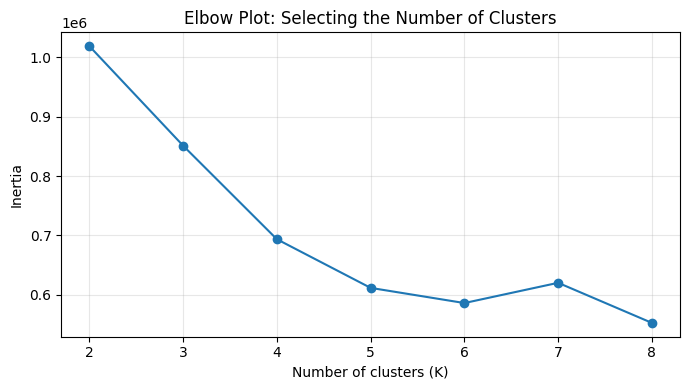

In [37]:
import matplotlib.pyplot as plt

# Graph 1: Elbow plot to compare inertia across different K values.
plt.figure(figsize=(7, 4))
plt.plot(results_df["k"], results_df["inertia"], marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Plot: Selecting the Number of Clusters")
plt.xticks(results_df["k"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

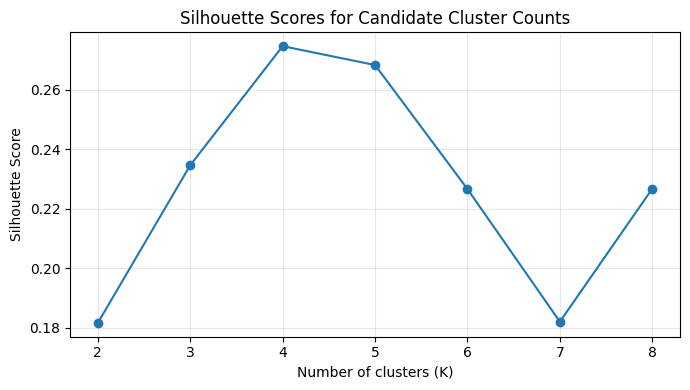

In [38]:
# Graph 2: Compare silhouette scores to assess cluster separation.
plt.figure(figsize=(7, 4))
plt.plot(
    results_df["k"],
    results_df["silhouette_sample"],
    marker="o"
)
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Candidate Cluster Counts")
plt.xticks(results_df["k"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

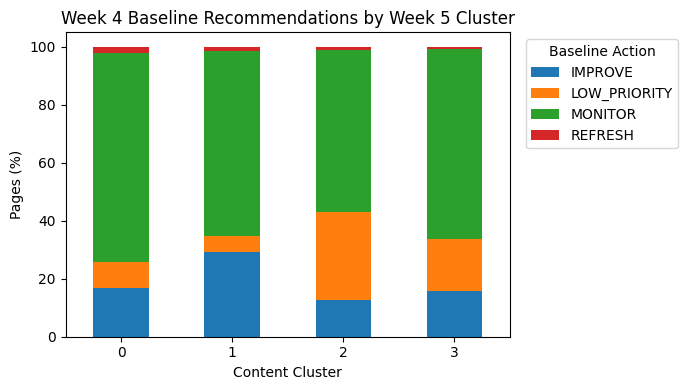

In [40]:
# Graph 3: Compare baseline action percentages across the four clusters.
action_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4)
)
plt.xlabel("Content Cluster")
plt.ylabel("Pages (%)")
plt.title("Week 4 Baseline Recommendations by Week 5 Cluster")
plt.xticks(rotation=0)
plt.legend(title="Baseline Action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Results and Baseline Comparison

I evaluated K-Means models with 2–8 clusters and selected **K = 4** based on the highest sampled silhouette score (0.275). The final model achieved a test silhouette score of **0.5297** on unseen clients. The clusters showed different traffic and content characteristics, with Cluster 2 having the highest median impressions and clicks.

I compared the four archetypes with the Week 4 baseline recommendations. All **159,830 clustered training records (100%)** matched a baseline action. `MONITOR` was the most common recommendation across all clusters, while Cluster 2 had the highest proportion of `LOW_PRIORITY` recommendations (30.1%). This comparison describes how the two approaches differ; it does not measure clustering accuracy because baseline actions are heuristic recommendations, not ground-truth labels.

In [ ]:
# Purpose: Check how many clustered training records matched a baseline
# recommendation and whether any records are missing an action label.

print("Clustered training records:", len(cluster_actions))
print("Matched baseline actions:", cluster_actions["action"].notna().sum())
print("Missing baseline actions:", cluster_actions["action"].isna().sum())
print("Match rate (%):", round(cluster_actions["action"].notna().mean() * 100, 2))

Clustered training records: 159830
Matched baseline actions: 159830
Missing baseline actions: 0
Match rate (%): 100.0


## 4. Errors and interpretation


**Findings:** The four-cluster model identified distinct content groups based mainly on traffic and content characteristics. Cluster 2 had the highest median impressions (28,891) and median clicks (58.5), while Cluster 1 had the lowest median impressions (68) and median clicks (0).

**Baseline comparison:** All 159,830 clustered training records matched a Week 4 baseline recommendation (100% match rate). The MONITOR action was the most common recommendation in every cluster. Cluster 2 had the highest proportion of LOW_PRIORITY recommendations (30.1%), despite having the highest median impressions and clicks. This highlights that the baseline heuristic and clustering model capture different characteristics.

**Limitations and potential errors:**
- The Week 4 baseline is a heuristic, not verified ground truth; agreement with it does not measure clustering accuracy.
- Median clicks were zero in Clusters 0 and 1, and median CTR was zero in all clusters except Cluster 2, where it was only 0.2%. Traffic alone does not establish content quality.
- Missing or unavailable analytics can affect the interpretation of page performance.
- Four clusters were selected based on silhouette scores and practical interpretability; other cluster counts may produce different archetypes.
- The model was trained on one month of performance data, so the results may not represent long-term patterns or seasonal changes.

**Conclusion:** The archetypes can support content prioritization, but recommendations should also consider publication status, deletion status, data availability, and business context before action is taken.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.